### UNDERSTANDING THE DATA

In [1]:
import os
from pathlib import Path

import yaml
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:


data_folder = Path("../dataset/IPL")

print("Current working directory:", os.getcwd())
print("Dataset folder exists:", data_folder.exists())


Current working directory: /Users/akarapuashmithareddy/Desktop/IPL_Score_Prediction/notebooks
Dataset folder exists: True


In [3]:

yaml_files = sorted(data_folder.glob("*.yaml"))

print("Total YAML files:", len(yaml_files))
print("First 5 files:", yaml_files[:5])

assert data_folder.exists(), "IPL dataset folder not found!"
assert len(yaml_files) > 0, "No YAML files found!"


Total YAML files: 1243
First 5 files: [PosixPath('../dataset/IPL/1082591.yaml'), PosixPath('../dataset/IPL/1082592.yaml'), PosixPath('../dataset/IPL/1082593.yaml'), PosixPath('../dataset/IPL/1082594.yaml'), PosixPath('../dataset/IPL/1082595.yaml')]


#### To inspect 1 match 

In [4]:
import yaml

with open(yaml_files[0], "r") as file:
    match = yaml.safe_load(file)

In [5]:
match_info = match['info']

print("Teams:", match_info['teams'])
print("Venue:", match_info['venue'])
print("Overs:", match_info['overs'])

Teams: ['Sunrisers Hyderabad', 'Royal Challengers Bangalore']
Venue: Rajiv Gandhi International Stadium, Uppal
Overs: 20


### EDA

#### Creating a DataFrame

In [6]:
matches_data = []

for file_path in yaml_files:

    with open(file_path, "r") as file:
        match = yaml.safe_load(file)

    match_info = match['info']

    match_data = {
        'date': match_info['dates'][0],
        'teams': match_info['teams'],
        'venue': match_info.get('venue'),
        'city': match_info.get('city'),
        'winner': match_info.get('outcome', {}).get('winner')
    }

    matches_data.append(match_data)

In [7]:
print("Total matches:", len(matches_data))

matches_df = pd.DataFrame(matches_data)

display(matches_df.head())

Total matches: 1243


,date,teams,venue,city,winner
0,2017-04-05,"[Sunrisers Hyderabad, Royal Challengers Bangal...","Rajiv Gandhi International Stadium, Uppal",Hyderabad,Sunrisers Hyderabad
1,2017-04-06,"[Rising Pune Supergiant, Mumbai Indians]",Maharashtra Cricket Association Stadium,Pune,Rising Pune Supergiant
2,2017-04-07,"[Gujarat Lions, Kolkata Knight Riders]",Saurashtra Cricket Association Stadium,Rajkot,Kolkata Knight Riders
3,2017-04-08,"[Kings XI Punjab, Rising Pune Supergiant]",Holkar Cricket Stadium,Indore,Kings XI Punjab
4,2017-04-08,"[Royal Challengers Bangalore, Delhi Daredevils]",M.Chinnaswamy Stadium,Bengaluru,Royal Challengers Bangalore


In [8]:
matches_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1243 entries, 0 to 1242
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   date    1243 non-null   object
 1   teams   1243 non-null   object
 2   venue   1243 non-null   object
 3   city    1192 non-null   object
 4   winner  1218 non-null   object
dtypes: object(5)
memory usage: 48.7+ KB


In [9]:

matches_df.isnull().sum()


date       0
teams      0
venue      0
city      51
winner    25
dtype: int64

In [10]:

matches_df[matches_df['winner'].isnull()]


,date,teams,venue,city,winner
33,2017-04-29,"[Gujarat Lions, Mumbai Indians]",Saurashtra Cricket Association Stadium,Rajkot,None
128,2019-03-30,"[Kolkata Knight Riders, Delhi Capitals]",Arun Jaitley Stadium,Delhi,None
167,2019-04-30,"[Royal Challengers Bangalore, Rajasthan Royals]",M.Chinnaswamy Stadium,Bengaluru,None
169,2019-05-02,"[Mumbai Indians, Sunrisers Hyderabad]",Wankhede Stadium,Mumbai,None
180,2020-09-20,"[Delhi Capitals, Kings XI Punjab]",Dubai International Cricket Stadium,None,None
199,2020-10-18,"[Kolkata Knight Riders, Sunrisers Hyderabad]",Sheikh Zayed Stadium,Abu Dhabi,None
204,2020-10-18,"[Mumbai Indians, Kings XI Punjab]",Dubai International Cricket Stadium,None,None
234,2020-09-28,"[Royal Challengers Bangalore, Mumbai Indians]",Dubai International Cricket Stadium,None,None
258,2021-04-25,"[Delhi Capitals, Sunrisers Hyderabad]","MA Chidambaram Stadium, Chepauk, Chennai",Chennai,None
417,2023-05-03,"[Lucknow Super Giants, Chennai Super Kings]",Bharat Ratna Shri Atal Bihari Vajpayee Ekana C...,Lucknow,None


In [11]:

outcome_types = {}

for file_path in yaml_files:

    with open(file_path, "r") as file:
        match = yaml.safe_load(file)

    outcome = match['info'].get('outcome', {})

    result = outcome.get('result', 'normal')

    outcome_types[result] = outcome_types.get(result, 0) + 1

print(outcome_types)


{'normal': 1218, 'tie': 16, 'no result': 9}


In [12]:

# Handle missing winners in tied matches

for index in matches_df[
    matches_df['winner'].isnull()
].index:

    with open(yaml_files[index], 'r') as file:
        match = yaml.safe_load(file)

    outcome = match['info'].get('outcome', {})

    if outcome.get('result') == 'tie':
        matches_df.loc[index, 'winner'] = (
            outcome.get('eliminator')
        )

print(
    "Missing winners after tie handling:",
    matches_df['winner'].isnull().sum()
)


Missing winners after tie handling: 9


In [13]:

# Fill missing city values where the venue is known

venue_to_city = {
    'Dubai International Cricket Stadium': 'Dubai',
    'Sharjah Cricket Stadium': 'Sharjah'
}

for venue, city in venue_to_city.items():

    mask = (
        (matches_df['venue'] == venue) &
        (matches_df['city'].isnull())
    )

    matches_df.loc[mask, 'city'] = city


In [14]:

print("Missing cities:", matches_df['city'].isnull().sum())


Missing cities: 0


In [15]:

# Convert date column to datetime

matches_df['date'] = pd.to_datetime(matches_df['date'])

# Extract season year
matches_df['year'] = matches_df['date'].dt.year

display(matches_df.head())


,date,teams,venue,city,winner,year
0,2017-04-05,"[Sunrisers Hyderabad, Royal Challengers Bangal...","Rajiv Gandhi International Stadium, Uppal",Hyderabad,Sunrisers Hyderabad,2017
1,2017-04-06,"[Rising Pune Supergiant, Mumbai Indians]",Maharashtra Cricket Association Stadium,Pune,Rising Pune Supergiant,2017
2,2017-04-07,"[Gujarat Lions, Kolkata Knight Riders]",Saurashtra Cricket Association Stadium,Rajkot,Kolkata Knight Riders,2017
3,2017-04-08,"[Kings XI Punjab, Rising Pune Supergiant]",Holkar Cricket Stadium,Indore,Kings XI Punjab,2017
4,2017-04-08,"[Royal Challengers Bangalore, Delhi Daredevils]",M.Chinnaswamy Stadium,Bengaluru,Royal Challengers Bangalore,2017


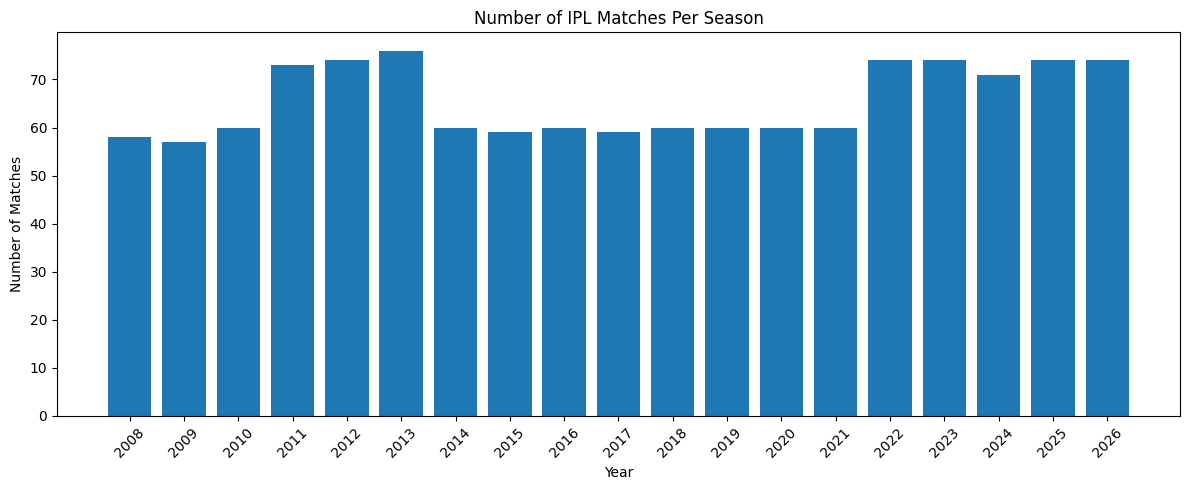

In [16]:

# Matches per year

matches_per_year = (
    matches_df['year'].value_counts().sort_index()
)

plt.figure(figsize=(12, 5))

plt.bar(
    matches_per_year.index,
    matches_per_year.values
)

plt.xlabel("Year")
plt.ylabel("Number of Matches")
plt.title("Number of IPL Matches Per Season")

plt.xticks(matches_per_year.index, rotation=45)
plt.tight_layout()
plt.show()


In [17]:
matches_df[matches_df['city'].isnull()]

,date,teams,venue,city,winner,year


In [18]:
all_teams = set()

for teams in matches_df['teams']:
    for team in teams:
        all_teams.add(team)

print("Total unique teams:", len(all_teams))
print(all_teams)

Total unique teams: 19
{'Royal Challengers Bengaluru', 'Delhi Capitals', 'Delhi Daredevils', 'Pune Warriors', 'Lucknow Super Giants', 'Gujarat Lions', 'Rising Pune Supergiant', 'Kings XI Punjab', 'Gujarat Titans', 'Kochi Tuskers Kerala', 'Royal Challengers Bangalore', 'Chennai Super Kings', 'Rajasthan Royals', 'Punjab Kings', 'Kolkata Knight Riders', 'Mumbai Indians', 'Sunrisers Hyderabad', 'Rising Pune Supergiants', 'Deccan Chargers'}


In [19]:
from collections import Counter

team_counts = Counter()

for teams in matches_df['teams']:
    for team in teams:
        team_counts[team] += 1

print(team_counts)

Counter({'Mumbai Indians': 291, 'Kolkata Knight Riders': 278, 'Chennai Super Kings': 266, 'Rajasthan Royals': 251, 'Royal Challengers Bangalore': 240, 'Sunrisers Hyderabad': 211, 'Kings XI Punjab': 190, 'Delhi Daredevils': 161, 'Delhi Capitals': 120, 'Punjab Kings': 88, 'Gujarat Titans': 77, 'Deccan Chargers': 75, 'Lucknow Super Giants': 72, 'Royal Challengers Bengaluru': 46, 'Pune Warriors': 46, 'Gujarat Lions': 30, 'Rising Pune Supergiant': 16, 'Kochi Tuskers Kerala': 14, 'Rising Pune Supergiants': 14})


#### Standardizing IPL Team Names

Some IPL franchises have changed their names over the years.

To maintain consistency during analysis and model development,
we standardize historical team names to their current names.

In [20]:
# To map old and new team namaes
team_name_mapping = {
    'Delhi Daredevils': 'Delhi Capitals',
    'Kings XI Punjab': 'Punjab Kings',
    'Royal Challengers Bangalore': 'Royal Challengers Bengaluru',
    'Rising Pune Supergiants': 'Rising Pune Supergiant'
}

In [21]:
matches_df['teams'] = matches_df['teams'].apply(
    lambda teams: [team_name_mapping.get(team, team) for team in teams]
)

In [22]:
all_teams = sorted({
    team
    for teams in matches_df['teams']
    for team in teams
})

print("Total unique teams:", len(all_teams))
print(all_teams)

Total unique teams: 15
['Chennai Super Kings', 'Deccan Chargers', 'Delhi Capitals', 'Gujarat Lions', 'Gujarat Titans', 'Kochi Tuskers Kerala', 'Kolkata Knight Riders', 'Lucknow Super Giants', 'Mumbai Indians', 'Pune Warriors', 'Punjab Kings', 'Rajasthan Royals', 'Rising Pune Supergiant', 'Royal Challengers Bengaluru', 'Sunrisers Hyderabad']


In [23]:
# Standardize old and new team names in the winner column
matches_df['winner'] = matches_df['winner'].replace(team_name_mapping)

In [24]:
print("Missing winners:", matches_df['winner'].isnull().sum())
print("Unique winners:", matches_df['winner'].nunique())

Missing winners: 9
Unique winners: 15


In [25]:
with open(yaml_files[0], 'r') as file:
    match = yaml.safe_load(file)

first_innings = match['innings'][0]['1st innings']

print("First innings keys:", first_innings.keys())
print("Batting team:", first_innings['team'])
print("Total overs recorded:", len(first_innings['deliveries']))

# Inspect the first delivery
first_over = first_innings['deliveries'][0]

print("First over details:", first_over)

First innings keys: dict_keys(['team', 'deliveries'])
Batting team: Sunrisers Hyderabad
Total overs recorded: 125
First over details: {0.1: {'actual_delivery': '0.1', 'batsman': 'DA Warner', 'bowler': 'TS Mills', 'non_striker': 'S Dhawan', 'runs': {'batsman': 0, 'extras': 0, 'total': 0}}}


In [26]:
deliveries = first_innings['deliveries']

print("Number of recorded overs:", len(deliveries))
print("First two overs:", deliveries[:2])

Number of recorded overs: 125
First two overs: [{0.1: {'actual_delivery': '0.1', 'batsman': 'DA Warner', 'bowler': 'TS Mills', 'non_striker': 'S Dhawan', 'runs': {'batsman': 0, 'extras': 0, 'total': 0}}}, {0.2: {'actual_delivery': '0.2', 'batsman': 'DA Warner', 'bowler': 'TS Mills', 'non_striker': 'S Dhawan', 'runs': {'batsman': 0, 'extras': 0, 'total': 0}}}]


In [27]:
# To extract the inner dictionary
delivery = list(deliveries[0].values())[0]

print(delivery)

{'actual_delivery': '0.1', 'batsman': 'DA Warner', 'bowler': 'TS Mills', 'non_striker': 'S Dhawan', 'runs': {'batsman': 0, 'extras': 0, 'total': 0}}


In [28]:
# To inspect types of dismissals
all_wicket_types = set()

for file_path in yaml_files:
    with open(file_path, 'r') as file:
        match = yaml.safe_load(file)

    first_innings = match['innings'][0]
    innings_data = list(first_innings.values())[0]

    for ball in innings_data['deliveries']:
        delivery_data = list(ball.values())[0]

        if 'wicket' in delivery_data:
            all_wicket_types.add(delivery_data['wicket']['kind'])

print(sorted(all_wicket_types))


['bowled', 'caught', 'caught and bowled', 'hit wicket', 'lbw', 'obstructing the field', 'retired hurt', 'retired out', 'run out', 'stumped']


In [29]:
valid_wickets = {
    'bowled',
    'caught',
    'caught and bowled',
    'hit wicket',
    'lbw',
    'obstructing the field',
    'retired out',
    'run out',
    'stumped'
}

In [30]:
wickets = 0

for ball in deliveries:
    delivery_data = list(ball.values())[0]

    if 'wicket' in delivery_data:
        wicket_type = delivery_data['wicket']['kind']

        if wicket_type in valid_wickets:
            wickets += 1

print("Total wickets:", wickets)

Total wickets: 4


In [31]:
total_runs = 0

for ball in deliveries:
    delivery_data = list(ball.values())[0]

    total_runs += delivery_data['runs']['total']

print("Total runs:", total_runs)

Total runs: 207


In [32]:
extras_types = set()

for ball in deliveries:
    delivery_data = list(ball.values())[0]

    if 'extras' in delivery_data:
        extras_types.update(delivery_data['extras'].keys())

print(extras_types)

{'noballs', 'wides', 'legbyes'}


In [33]:
legal_balls = 0

for ball in deliveries:
    delivery_data = list(ball.values())[0]

    extras = delivery_data.get('extras', {})

    if 'wides' not in extras and 'noballs' not in extras:
        legal_balls += 1

print("Legal balls:", legal_balls)

Legal balls: 120


In [34]:
overs = legal_balls / 6

run_rate = total_runs / overs if overs > 0 else 0

print("Overs:", overs)
print("Run rate:", round(run_rate, 2))

Overs: 20.0
Run rate: 10.35


In [35]:
empty_innings_matches = []

for file_path in yaml_files:
    with open(file_path, 'r') as file:
        match = yaml.safe_load(file)

    if not match.get('innings'):
        empty_innings_matches.append(file_path)

print("Matches with no innings:", len(empty_innings_matches))

Matches with no innings: 0


### Extracting First Innings Statistics

In [36]:
def extract_first_innings(match):
    
    first_innings = match['innings'][0]
    innings_data = list(first_innings.values())[0]

    deliveries = innings_data['deliveries']

    total_runs = 0
    wickets = 0
    legal_balls = 0

    for ball in deliveries:

        delivery_data = list(ball.values())[0]

        # Calculate total runs
        total_runs += delivery_data['runs']['total']

        # Calculate wickets
        if 'wicket' in delivery_data:
            wicket_type = delivery_data['wicket']['kind']

            if wicket_type in valid_wickets:
                wickets += 1

        # Calculate legal balls
        extras = delivery_data.get('extras', {})

        if 'wides' not in extras and 'noballs' not in extras:
            legal_balls += 1

    return total_runs, wickets, legal_balls

In [37]:
all_matches_runs = []
all_matches_wickets = []
all_matches_legal_balls = []

for file_path in yaml_files:

    with open(file_path, 'r') as file:
        match = yaml.safe_load(file)

    if not match.get('innings'):
        continue

    runs, wickets, legal_balls = extract_first_innings(match)

    all_matches_runs.append(runs)
    all_matches_wickets.append(wickets)
    all_matches_legal_balls.append(legal_balls)

print("Total matches processed:", len(all_matches_runs))
print("First 10 innings scores:", all_matches_runs[:10])

Total matches processed: 1243
First 10 innings scores: [207, 184, 183, 163, 157, 135, 178, 148, 205, 158]


In [38]:
# Create a DataFrame containing first innings statistics

scores_df = pd.DataFrame({
    'first_innings_score': all_matches_runs,
    'first_innings_wickets': all_matches_wickets,
    'first_innings_legal_balls': all_matches_legal_balls
})

scores_df.head()

,first_innings_score,first_innings_wickets,first_innings_legal_balls
0,207,4,120
1,184,8,120
2,183,4,120
3,163,6,120
4,157,8,120


In [39]:
scores_df.shape

(1243, 3)

In [40]:
scores_df.describe()

,first_innings_score,first_innings_wickets,first_innings_legal_balls
count,1243.000000,1243.000000,1243.000000
mean,168.569590,6.123894,118.662912
std,34.053296,2.129639,7.310227
min,25.000000,0.000000,22.000000
25%,148.000000,4.500000,120.000000
50%,168.000000,6.000000,120.000000
75%,190.000000,8.000000,120.000000
max,287.000000,10.000000,121.000000


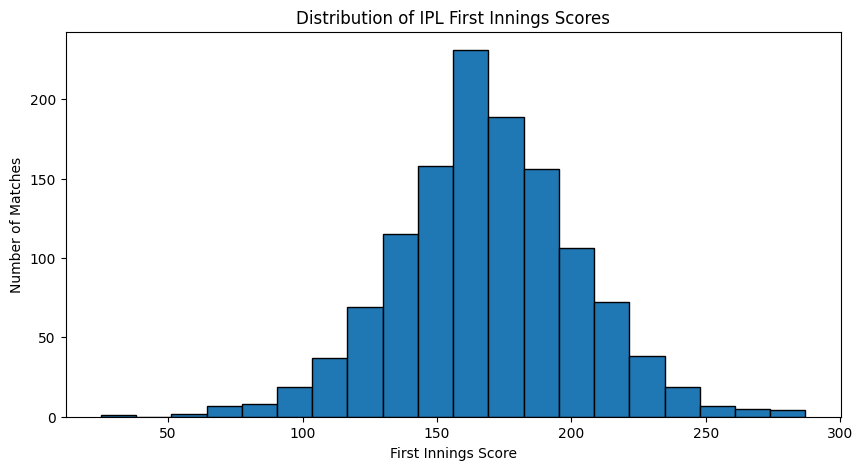

In [41]:
plt.figure(figsize=(10, 5))

plt.hist(
    scores_df['first_innings_score'],
    bins=20,
    edgecolor='black'
)

plt.xlabel('First Innings Score')
plt.ylabel('Number of Matches')
plt.title('Distribution of IPL First Innings Scores')

plt.show()

In [42]:
matches_df_copy = matches_df.copy()

matches_df_copy['teams'] = matches_df_copy['teams'].apply(tuple)

matches_df_copy.duplicated().sum()

np.int64(0)

In [43]:
def create_snapshots(deliveries, final_score, match_id):

    legal_balls = 0
    total_runs = 0
    wickets = 0

    snapshots = []

    recent_runs = []
    pending_runs = 0

    for ball in deliveries:

        delivery_data = list(ball.values())[0]
        extras = delivery_data.get('extras', {})

        is_legal_ball = 'wides' not in extras and 'noballs' not in extras

        total_runs += delivery_data['runs']['total']
        pending_runs += delivery_data['runs']['total']

        if 'wicket' in delivery_data:
            wicket_type = delivery_data['wicket']['kind']

            if wicket_type in valid_wickets:
                wickets += 1

        if is_legal_ball:

            legal_balls += 1

            recent_runs.append(pending_runs)
            pending_runs = 0

            current_run_rate = (total_runs / legal_balls) * 6

            runs_last_6_balls = sum(recent_runs[-6:])
            runs_last_12_balls = sum(recent_runs[-12:])
            runs_last_30_balls = sum(recent_runs[-30:])

            snapshot = {
                'match_id': match_id,
                'legal_balls': legal_balls,
                'overs_completed': legal_balls / 6,
                'current_runs': total_runs,
                'wickets': wickets,
                'current_run_rate': current_run_rate,
                'runs_last_6_balls': runs_last_6_balls,
                'runs_last_12_balls': runs_last_12_balls,
                'runs_last_30_balls': runs_last_30_balls,
                'final_score': final_score
            }

            snapshots.append(snapshot)

    return snapshots

In [44]:
test_match_id = 0

with open(yaml_files[test_match_id], 'r') as file:
    test_match = yaml.safe_load(file)

first_innings = test_match['innings'][0]
innings_data = list(first_innings.values())[0]
deliveries = innings_data['deliveries']

final_score = extract_first_innings(test_match)

match_id = os.path.splitext(os.path.basename(yaml_files[test_match_id]))[0]

test_snapshots = create_snapshots(
    deliveries, final_score, match_id
)

test_df = pd.DataFrame(test_snapshots)

print("Test match ID:", match_id)
print("Total test snapshots:", len(test_df))
test_df.head()

Test match ID: 1082591
Total test snapshots: 120


,match_id,legal_balls,overs_completed,current_runs,wickets,current_run_rate,runs_last_6_balls,runs_last_12_balls,runs_last_30_balls,final_score
0,1082591,1,0.166667,0,0,0.0,0,0,0,"(207, 4, 120)"
1,1082591,2,0.333333,0,0,0.0,0,0,0,"(207, 4, 120)"
2,1082591,3,0.500000,4,0,8.0,4,4,4,"(207, 4, 120)"
3,1082591,4,0.666667,4,0,6.0,4,4,4,"(207, 4, 120)"
4,1082591,5,0.833333,6,0,7.2,6,6,6,"(207, 4, 120)"


In [45]:
all_snapshots = []

for file_path in yaml_files:

    with open(file_path, 'r') as file:
        match = yaml.safe_load(file)

    if not match or not match.get('innings'):
        continue

    first_innings = match['innings'][0]
    innings_data = list(first_innings.values())[0]
    deliveries = innings_data['deliveries']

    final_score = extract_first_innings(match)

    match_id = os.path.splitext(os.path.basename(file_path))[0]

    match_snapshots = create_snapshots(
        deliveries, final_score, match_id
    )

    all_snapshots.extend(match_snapshots)

snapshots_df = pd.DataFrame(all_snapshots)

print("Total matches processed:", snapshots_df['match_id'].nunique())
print("Total snapshots generated:", len(snapshots_df))

Total matches processed: 1243
Total snapshots generated: 147498


In [46]:
snapshots_df.shape

(147498, 10)

In [47]:
snapshots_df[snapshots_df['legal_balls'] > 120]

,match_id,legal_balls,overs_completed,current_runs,wickets,current_run_rate,runs_last_6_balls,runs_last_12_balls,runs_last_30_balls,final_score
98713,419155,121,20.166667,112,9,5.553719,12,22,37,"(112, 9, 121)"


In [48]:
match_id = 987

print("Match ID:", match_id)
print("YAML file:", yaml_files[match_id])

Match ID: 987
YAML file: ../dataset/IPL/548381.yaml


In [49]:
snapshots_df.describe()

,legal_balls,overs_completed,current_runs,wickets,current_run_rate,runs_last_6_balls,runs_last_12_balls,runs_last_30_balls
count,147498.000000,147498.000000,147498.000000,147498.000000,147498.000000,147498.000000,147498.000000,147498.000000
mean,60.056448,10.009408,79.625541,2.437179,7.679913,8.276594,15.988752,36.038184
std,34.517295,5.752882,51.892080,2.046184,2.424175,4.758221,7.635842,16.358184
min,1.000000,0.166667,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,5.000000,37.000000,1.000000,6.352941,5.000000,11.000000,26.000000
50%,60.000000,10.000000,75.000000,2.000000,7.670886,8.000000,15.000000,37.000000
75%,90.000000,15.000000,117.000000,4.000000,8.965517,11.000000,21.000000,47.000000
max,121.000000,20.166667,287.000000,10.000000,42.000000,39.000000,64.000000,117.000000


In [50]:
print("Total matches:", snapshots_df['match_id'].nunique())
print("Total snapshots:", len(snapshots_df))

Total matches: 1243
Total snapshots: 147498


In [51]:
# Feature Engineering

# Balls remaining in the innings
snapshots_df['balls_remaining'] = 120 - snapshots_df['legal_balls']

# Wickets remaining
snapshots_df['wickets_remaining'] = 10 - snapshots_df['wickets']

In [52]:
print("Dataset shape:", snapshots_df.shape)

print("\nFeature preview:")

print(
    snapshots_df[
        [
            'legal_balls',
            'current_runs',
            'wickets',
            'current_run_rate',
            'runs_last_6_balls',
            'runs_last_12_balls',
            'runs_last_30_balls',
            'balls_remaining',
            'wickets_remaining',
            'final_score'
        ]
    ].head(15)
)

Dataset shape: (147498, 12)

Feature preview:
    legal_balls  current_runs  wickets  current_run_rate  runs_last_6_balls  \
0             1             0        0          0.000000                  0   
1             2             0        0          0.000000                  0   
2             3             4        0          8.000000                  4   
3             4             4        0          6.000000                  4   
4             5             6        0          7.200000                  6   
5             6             7        0          7.000000                  7   
6             7             8        0          6.857143                  8   
7             8            12        0          9.000000                 12   
8             9            19        0         12.666667                 15   
9            10            19        1         11.400000                 15   
10           11            19        1         10.363636                 13   
11    

In [53]:

# Create match-to-season mapping using the same
# YAML file order used when generating snapshots.

from pathlib import Path
import pandas as pd
import yaml

match_year_data = []

for match_id, file_path in enumerate(yaml_files):

    with open(file_path, 'r') as file:
        match = yaml.safe_load(file)

    match_date = match['info']['dates'][0]

    match_year_data.append({
        'match_id': str(match_id),
        'yaml_file': Path(file_path).name,
        'year': pd.to_datetime(match_date).year
    })

match_year_df = pd.DataFrame(match_year_data)

# Data integrity checks
assert match_year_df['match_id'].is_unique
assert len(match_year_df) == len(yaml_files)

print("Total matches:", len(match_year_df))
print("Unique seasons:", match_year_df['year'].nunique())

display(match_year_df.head())


Total matches: 1243
Unique seasons: 19


,match_id,yaml_file,year
0,0,1082591.yaml,2017
1,1,1082592.yaml,2017
2,2,1082593.yaml,2017
3,3,1082594.yaml,2017
4,4,1082595.yaml,2017


In [63]:
match_year_df['match_id'] = (
    match_year_df['yaml_file']
    .str.replace('.yaml', '', regex=False)
)

In [64]:

# Attach season information to the snapshot dataset

snapshots_df['match_id'] = (
    snapshots_df['match_id'].astype(str)
)

snapshots_with_year = snapshots_df.merge(
    match_year_df[['match_id', 'year']],
    on='match_id',
    how='left',
    validate='many_to_one'
)

# Verify successful mapping
missing_years = snapshots_with_year['year'].isna().sum()

print("Missing years:", missing_years)

assert missing_years == 0, "Some snapshots have missing season information!"

print("\nSnapshots by season:")

display(
    snapshots_with_year.groupby('year').size()
)


Missing years: 0

Snapshots by season:


year
2008    6801
2009    6776
2010    7188
2011    8573
2012    8813
2013    9033
2014    7138
2015    6895
2016    7141
2017    7023
2018    7121
2019    7093
2020    7200
2021    7192
2022    8816
2023    8861
2024    8465
2025    8688
2026    8681
dtype: int64

In [65]:
#split by season
train_data = snapshots_with_year[
    snapshots_with_year['year'] <= 2023
].copy()

test_data = snapshots_with_year[
    snapshots_with_year['year'] >= 2024
].copy()

print("Training matches:", train_data['match_id'].nunique())
print("Testing matches:", test_data['match_id'].nunique())

print("Training snapshots:", len(train_data))
print("Testing snapshots:", len(test_data))

Training matches: 1024
Testing matches: 219
Training snapshots: 121664
Testing snapshots: 25834


In [66]:
# prepare features
features = [
    'legal_balls',
    'overs_completed',
    'current_runs',
    'wickets',
    'current_run_rate',
    'runs_last_30_balls',
    'balls_remaining',
    'wickets_remaining',
    'runs_last_6_balls',
    'runs_last_12_balls'
]

X_train_time = train_data[features]
y_train_time = train_data['final_score']

X_test_time = test_data[features]
y_test_time = test_data['final_score']

In [67]:
# train
time_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    min_samples_leaf=10,
    random_state=42
)

time_model.fit(X_train_time, y_train_time)

time_pred = time_model.predict(X_test_time)

NameError: name 'GradientBoostingRegressor' is not defined

In [68]:
# evaluate
time_mae = mean_absolute_error(y_test_time, time_pred)

time_rmse = np.sqrt(
    mean_squared_error(y_test_time, time_pred)
)

print("Chronological Test MAE:", time_mae)
print("Chronological Test RMSE:", time_rmse)

NameError: name 'mean_absolute_error' is not defined

In [ ]:
# Simple run-rate baseline
baseline_time_pred = X_test_time['current_run_rate'] * 20

# Calculate baseline metrics
baseline_time_mae = mean_absolute_error(
    y_test_time, baseline_time_pred
)

baseline_time_rmse = np.sqrt(
    mean_squared_error(y_test_time, baseline_time_pred)
)

# Compare both models
comparison_time = pd.DataFrame({
    'Model': [
        'Simple Run Rate Baseline',
        'Tuned Gradient Boosting'
    ],
    'MAE': [
        baseline_time_mae,
        time_mae
    ],
    'RMSE': [
        baseline_time_rmse,
        time_rmse
    ]
})

display(comparison_time)

,Model,MAE,RMSE
0,Simple Run Rate Baseline,28.898472,46.754993
1,Tuned Gradient Boosting,20.646675,28.570304


In [ ]:
# finding where the chronological model struggles
chron_results = pd.DataFrame({
    'legal_balls': X_test_time['legal_balls'],
    'actual_score': y_test_time,
    'predicted_score': time_pred
})

chron_results['absolute_error'] = abs(
    chron_results['actual_score'] -
    chron_results['predicted_score']
)

chron_results['squared_error'] = (
    chron_results['actual_score'] -
    chron_results['predicted_score']
) ** 2

chron_results['innings_stage'] = pd.cut(
    chron_results['legal_balls'],
    bins=[0, 30, 60, 90, 120],
    labels=[
        'Overs 1-5',
        'Overs 6-10',
        'Overs 11-15',
        'Overs 16-20'
    ]
)

chron_stage_results = chron_results.groupby(
    'innings_stage',
    observed=False
).agg(
    MAE=('absolute_error', 'mean'),
    MSE=('squared_error', 'mean'),
    Samples=('actual_score', 'count')
)

chron_stage_results['RMSE'] = np.sqrt(
    chron_stage_results['MSE']
)

chron_stage_results = chron_stage_results.drop(
    columns=['MSE']
)

display(chron_stage_results)



,MAE,Samples,RMSE
innings_stage,,,
Overs 1-5,32.897204,6562,41.188083
Overs 6-10,24.491223,6540,30.699154
Overs 11-15,16.061235,6476,21.041431
Overs 16-20,8.524551,6256,12.155873


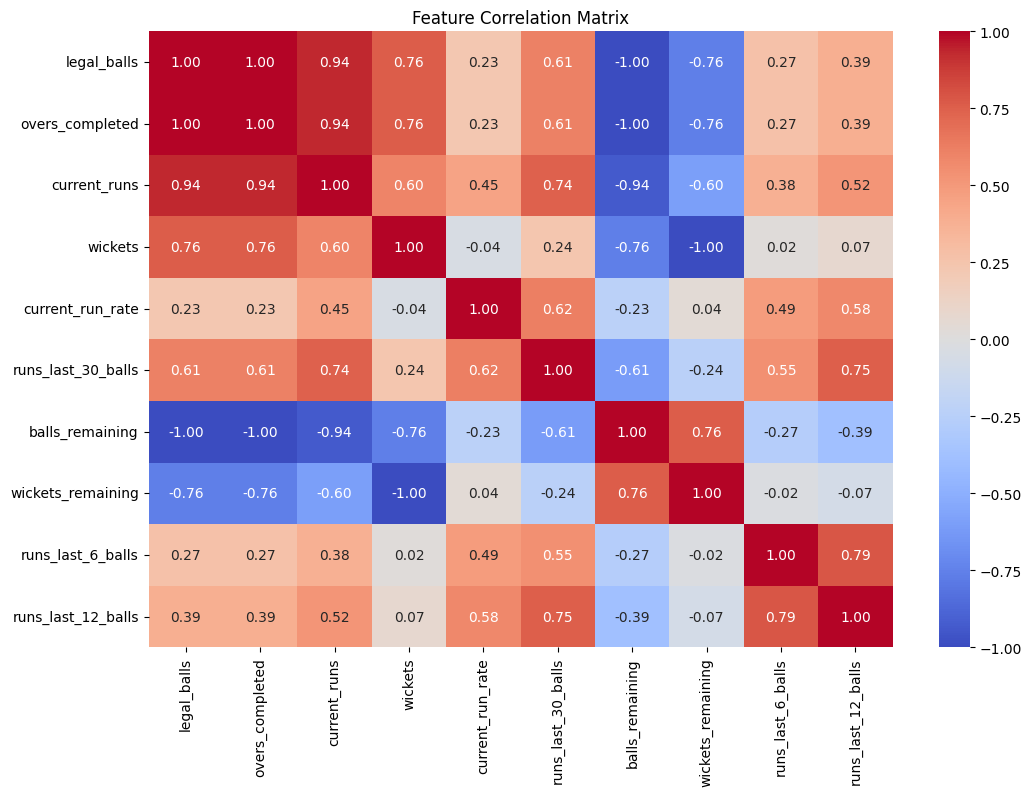

In [ ]:
#inspecting current features
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

correlation = X_train_time.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Feature Correlation Matrix')

plt.show()

In [ ]:
reduced_features = [
    'legal_balls',
    'current_runs',
    'wickets',
    'current_run_rate',
    'runs_last_30_balls',
    'runs_last_6_balls',
    'runs_last_12_balls'
]

In [ ]:
X_train_reduced = X_train_time[reduced_features]
X_test_reduced = X_test_time[reduced_features]

reduced_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    min_samples_leaf=10,
    random_state=42
)

reduced_model.fit(X_train_reduced, y_train_time)

reduced_pred = reduced_model.predict(X_test_reduced)

print("Reduced Model MAE:", mean_absolute_error(y_test_time, reduced_pred))
print("Reduced Model RMSE:", mean_squared_error(y_test_time, reduced_pred) ** 0.5)

Reduced Model MAE: 20.647461201953007
Reduced Model RMSE: 28.57284164795197


In [ ]:
matches_with_id = matches_df.copy()

matches_with_id['match_id'] = range(len(matches_with_id))

matches_with_id['match_id'] = matches_with_id['match_id'].astype(str)

print(matches_with_id[['match_id', 'venue']].head())

  match_id                                              venue
0        0                         Subrata Roy Sahara Stadium
1        1            Maharashtra Cricket Association Stadium
2        2                              M Chinnaswamy Stadium
3        3  Punjab Cricket Association IS Bindra Stadium, ...
4        4                              M Chinnaswamy Stadium


In [ ]:
snapshots_with_year = snapshots_with_year.merge(
    matches_with_id[['match_id', 'venue']],
    on='match_id',
    how='left'
)

In [ ]:
print(snapshots_with_year[['match_id', 'year', 'venue']].head())

print("Missing venues:", snapshots_with_year['venue'].isnull().sum())

print("Unique venues:", snapshots_with_year['venue'].nunique())

  match_id  year                       venue
0        0  2013  Subrata Roy Sahara Stadium
1        0  2013  Subrata Roy Sahara Stadium
2        0  2013  Subrata Roy Sahara Stadium
3        0  2013  Subrata Roy Sahara Stadium
4        0  2013  Subrata Roy Sahara Stadium
Missing venues: 0
Unique venues: 60


In [ ]:
X_train_venue = X_train_time[reduced_features].copy()
X_test_venue = X_test_time[reduced_features].copy()

X_train_venue['venue'] = snapshots_with_year.loc[X_train_time.index, 'venue']
X_test_venue['venue'] = snapshots_with_year.loc[X_test_time.index, 'venue']

print(X_train_venue[['venue']].head())

                        venue
0  Subrata Roy Sahara Stadium
1  Subrata Roy Sahara Stadium
2  Subrata Roy Sahara Stadium
3  Subrata Roy Sahara Stadium
4  Subrata Roy Sahara Stadium


In [ ]:
# applying one hot encoding
from sklearn.preprocessing import OneHotEncoder
import pandas as pd

# Create the encoder
encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

# Learn venue categories from training data
train_venue_encoded = encoder.fit_transform(
    X_train_venue[['venue']]
)

# Transform test venues using the same encoder
test_venue_encoded = encoder.transform(
    X_test_venue[['venue']]
)

# Convert encoded arrays into DataFrames
train_venue_df = pd.DataFrame(
    train_venue_encoded,
    columns=encoder.get_feature_names_out(['venue']),
    index=X_train_venue.index
)

test_venue_df = pd.DataFrame(
    test_venue_encoded,
    columns=encoder.get_feature_names_out(['venue']),
    index=X_test_venue.index
)

print("Training venue features:", train_venue_df.shape)
print("Testing venue features:", test_venue_df.shape)

Training venue features: (121663, 56)
Testing venue features: (25834, 56)


In [ ]:
# Combine numerical features and venue features

X_train_final = pd.concat(
    [X_train_venue[reduced_features], train_venue_df],
    axis=1
)

X_test_final = pd.concat(
    [X_test_venue[reduced_features], test_venue_df],
    axis=1
)

print("Training shape:", X_train_final.shape)
print("Testing shape:", X_test_final.shape)

Training shape: (121663, 63)
Testing shape: (25834, 63)


In [ ]:
venue_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    min_samples_leaf=10,
    random_state=42
)

venue_model.fit(X_train_final, y_train_time)

venue_pred = venue_model.predict(X_test_final)

venue_mae = mean_absolute_error(y_test_time, venue_pred)

venue_rmse = mean_squared_error(
    y_test_time,
    venue_pred
) ** 0.5

print("Venue Model MAE:", venue_mae)
print("Venue Model RMSE:", venue_rmse)

Venue Model MAE: 20.309531186998964
Venue Model RMSE: 27.53911577710308


In [ ]:
# evaluating performances at different stages
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

stage_results = pd.DataFrame({
    'legal_balls': X_test_time['legal_balls'],
    'actual': y_test_time,
    'predicted': venue_pred
})

stage_results['innings_stage'] = pd.cut(
    stage_results['legal_balls'],
    bins=[0, 30, 60, 90, 120],
    labels=['Overs 1-5', 'Overs 6-10', 'Overs 11-15', 'Overs 16-20']
)

results = []

for stage, group in stage_results.groupby('innings_stage', observed=True):

    mae = mean_absolute_error(
        group['actual'],
        group['predicted']
    )

    rmse = mean_squared_error(
        group['actual'],
        group['predicted']
    ) ** 0.5

    results.append({
        'Innings Stage': stage,
        'MAE': mae,
        'RMSE': rmse,
        'Samples': len(group)
    })

stage_comparison = pd.DataFrame(results)

print(stage_comparison)

  Innings Stage        MAE       RMSE  Samples
0     Overs 1-5  30.626057  38.605101     6562
1    Overs 6-10  23.167841  28.888297     6540
2   Overs 11-15  16.787407  21.727513     6476
3   Overs 16-20  10.146310  14.403123     6256


In [ ]:
#feature importance
importance_df = pd.DataFrame({
    'Feature': X_train_final.columns,
    'Importance': venue_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print(importance_df.head(20))

                                              Feature  Importance
3                                    current_run_rate    0.693193
2                                             wickets    0.179157
1                                        current_runs    0.060177
4                                  runs_last_30_balls    0.009570
0                                         legal_balls    0.008510
61                     venue_Wankhede Stadium, Mumbai    0.006862
21                        venue_Eden Gardens, Kolkata    0.005629
30             venue_M Chinnaswamy Stadium, Bengaluru    0.004542
29                        venue_M Chinnaswamy Stadium    0.002823
31                        venue_M.Chinnaswamy Stadium    0.002330
44  venue_Punjab Cricket Association IS Bindra Sta...    0.002312
37             venue_Narendra Modi Stadium, Ahmedabad    0.002240
8                   venue_Arun Jaitley Stadium, Delhi    0.002163
28                                    venue_Kingsmead    0.001938
40        

In [ ]:
# evaluating by season
season_results = pd.DataFrame({
    'year': snapshots_with_year.loc[X_test_time.index, 'year'].values,
    'actual': y_test_time.values,
    'without_venue': time_pred,
    'with_venue': venue_pred
})

for year, data in season_results.groupby('year'):

    mae_without = mean_absolute_error(
        data['actual'], data['without_venue']
    )

    mae_with = mean_absolute_error(
        data['actual'], data['with_venue']
    )

    print(f"\nSeason: {year}")
    print(f"Without venue MAE: {mae_without:.2f}")
    print(f"With venue MAE: {mae_with:.2f}")


Season: 2024
Without venue MAE: 21.10
With venue MAE: 20.97

Season: 2025
Without venue MAE: 19.87
With venue MAE: 19.35

Season: 2026
Without venue MAE: 20.98
With venue MAE: 20.63


In [ ]:
X_train_year = X_train_time[reduced_features].copy()
X_test_year = X_test_time[reduced_features].copy()

X_train_year['year'] = (
    snapshots_with_year.loc[X_train_time.index, 'year']
)

X_test_year['year'] = (
    snapshots_with_year.loc[X_test_time.index, 'year']
)

X_train_year['venue'] = (
    snapshots_with_year.loc[X_train_time.index, 'venue']
)

X_test_year['venue'] = (
    snapshots_with_year.loc[X_test_time.index, 'venue']
)

print(X_train_year.shape)
print(X_test_year.shape)

(121663, 9)
(25834, 9)


In [ ]:
from sklearn.preprocessing import OneHotEncoder

encoder_year = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

train_venue_year_encoded = encoder_year.fit_transform(
    X_train_year[['venue']]
)

test_venue_year_encoded = encoder_year.transform(
    X_test_year[['venue']]
)

print("Training encoded:", train_venue_year_encoded.shape)
print("Testing encoded:", test_venue_year_encoded.shape)

Training encoded: (121663, 56)
Testing encoded: (25834, 56)


In [ ]:
X_train_year_final = np.concatenate(
    [
        X_train_year[reduced_features + ['year']].values,
        train_venue_year_encoded
    ],
    axis=1
)

X_test_year_final = np.concatenate(
    [
        X_test_year[reduced_features + ['year']].values,
        test_venue_year_encoded
    ],
    axis=1
)

print("Training shape:", X_train_year_final.shape)
print("Testing shape:", X_test_year_final.shape)

Training shape: (121663, 64)
Testing shape: (25834, 64)


In [ ]:
# training our gradient boosting
year_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    min_samples_leaf=10,
    random_state=42
)

year_model.fit(X_train_year_final, y_train_time)

year_pred = year_model.predict(X_test_year_final)

year_mae = mean_absolute_error(y_test_time, year_pred)

year_rmse = np.sqrt(
    mean_squared_error(y_test_time, year_pred)
)

print("Year + Venue Model MAE:", year_mae)
print("Year + Venue Model RMSE:", year_rmse)

Year + Venue Model MAE: 19.02322346638258
Year + Venue Model RMSE: 25.920868022858482


In [ ]:
# the above thing improved our results
year_results = pd.DataFrame({
    'year': snapshots_with_year.loc[X_test_time.index, 'year'].values,
    'actual': y_test_time.values,
    'without_year': venue_pred,
    'with_year': year_pred
})

for year, data in year_results.groupby('year'):

    mae_without = mean_absolute_error(
        data['actual'], data['without_year']
    )

    mae_with = mean_absolute_error(
        data['actual'], data['with_year']
    )

    print(f"\nSeason: {year}")
    print(f"Without year MAE: {mae_without:.2f}")
    print(f"With year MAE: {mae_with:.2f}")
    # even this helped us very much


Season: 2024
Without year MAE: 20.97
With year MAE: 20.07

Season: 2025
Without year MAE: 19.35
With year MAE: 18.17

Season: 2026
Without year MAE: 20.63
With year MAE: 18.85


In [ ]:
# feature importance
feature_names = (
    reduced_features
    + ['year']
    + list(encoder_year.get_feature_names_out(['venue']))
)

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': year_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print(importance_df.head(20))

                                              Feature  Importance
3                                    current_run_rate    0.673167
2                                             wickets    0.170755
1                                        current_runs    0.058082
7                                                year    0.041730
4                                  runs_last_30_balls    0.009859
0                                         legal_balls    0.009541
30                        venue_M Chinnaswamy Stadium    0.004553
12  venue_Bharat Ratna Shri Atal Bihari Vajpayee E...    0.003367
22                        venue_Eden Gardens, Kolkata    0.002472
25  venue_Himachal Pradesh Cricket Association Sta...    0.002358
35     venue_MA Chidambaram Stadium, Chepauk, Chennai    0.002340
62                     venue_Wankhede Stadium, Mumbai    0.002269
61                             venue_Wankhede Stadium    0.001916
32                        venue_M.Chinnaswamy Stadium    0.001824
9         

In [ ]:
#permutation importance
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    year_model,
    X_test_year_final,
    y_test_time,
    scoring='neg_mean_absolute_error',
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': perm_result.importances_mean
})

permutation_df = permutation_df.sort_values(
    by='Importance',
    ascending=False
)

print(permutation_df.head(15))

                                              Feature  Importance
3                                    current_run_rate   11.622706
2                                             wickets    5.817827
1                                        current_runs    2.655843
0                                         legal_balls    1.217273
4                                  runs_last_30_balls    0.332470
35     venue_MA Chidambaram Stadium, Chepauk, Chennai    0.154113
12  venue_Bharat Ratna Shri Atal Bihari Vajpayee E...    0.084348
26  venue_Himachal Pradesh Cricket Association Sta...    0.061818
62                     venue_Wankhede Stadium, Mumbai    0.034833
22                        venue_Eden Gardens, Kolkata    0.020271
38             venue_Narendra Modi Stadium, Ahmedabad    0.010939
49  venue_Rajiv Gandhi International Stadium, Uppa...    0.005430
46   venue_Punjab Cricket Association Stadium, Mohali    0.000000
41                                     venue_Newlands    0.000000
39        

In [ ]:
# imp of year
year_importance = permutation_df[
    permutation_df['Feature'] == 'year'
]

venue_importance = permutation_df[
    permutation_df['Feature'].str.startswith('venue_')
]

print("Year permutation importance:")
print(year_importance)

print("\nTotal venue permutation importance:")
print(venue_importance['Importance'].sum())

print("\nAverage venue permutation importance:")
print(venue_importance['Importance'].mean())

Year permutation importance:
  Feature  Importance
7    year         0.0

Total venue permutation importance:
0.2244162636844962

Average venue permutation importance:
0.004007433280080289


In [ ]:
# remove year
print("Without year MAE:", 
      mean_absolute_error(y_test_time, venue_pred))

print("With year MAE:", 
      mean_absolute_error(y_test_time, year_pred))

print("\nWithout year RMSE:",
      np.sqrt(mean_squared_error(y_test_time, venue_pred)))

print("With year RMSE:",
      np.sqrt(mean_squared_error(y_test_time, year_pred)))

Without year MAE: 20.309531186998964
With year MAE: 19.02322346638258

Without year RMSE: 27.53911577710308
With year RMSE: 25.920868022858482


In [ ]:
# checking whether year is genuinely useful
venue_only_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    min_samples_leaf=10,
    random_state=42
)

venue_only_model.fit(X_train_final, y_train_time)

venue_only_pred = venue_only_model.predict(X_test_final)

print(
    "Venue-only MAE:",
    mean_absolute_error(y_test_time, venue_only_pred)
)

print(
    "Venue-only RMSE:",
    np.sqrt(mean_squared_error(y_test_time, venue_only_pred))
)


Venue-only MAE: 20.309531186998964
Venue-only RMSE: 27.53911577710308


In [ ]:
# checking year imp
perm_year_check = permutation_importance(
    year_model,
    X_test_year_final,
    y_test_time,
    scoring='neg_mean_absolute_error',
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

year_index = feature_names.index('year')

print("Year importance values:")
print(perm_year_check.importances[year_index])

print(
    "\nMean importance:",
    perm_year_check.importances_mean[year_index]
)

print(
    "Standard deviation:",
    perm_year_check.importances_std[year_index]
)

Year importance values:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

Mean importance: 0.0
Standard deviation: 0.0


In [ ]:
year_tree_usage = []

for tree in year_model.estimators_.ravel():

    tree_features = tree.tree_.feature

    year_splits = np.sum(tree_features == 7)

    year_tree_usage.append(year_splits)

print("Total trees:", len(year_tree_usage))

print("Trees using year:",
      sum(count > 0 for count in year_tree_usage))

print("Total year splits:",
      sum(year_tree_usage))

Total trees: 200
Trees using year: 140
Total year splits: 213


In [ ]:
year_thresholds = []

for tree in year_model.estimators_.ravel():

    tree_structure = tree.tree_

    for i in range(tree_structure.node_count):

        if tree_structure.feature[i] == 7:

            year_thresholds.append(
                tree_structure.threshold[i]
            )

print("Number of year splits:", len(year_thresholds))

print("Unique year thresholds:")

print(sorted(set(year_thresholds)))

Number of year splits: 213
Unique year thresholds:
[np.float64(2008.5), np.float64(2010.5), np.float64(2011.5), np.float64(2012.5), np.float64(2013.5), np.float64(2014.0), np.float64(2014.5), np.float64(2015.5), np.float64(2016.5), np.float64(2017.5), np.float64(2018.5), np.float64(2019.5), np.float64(2020.5), np.float64(2021.5), np.float64(2022.0), np.float64(2022.5)]


In [ ]:
validation_years = [2020, 2021, 2022, 2023]

for test_year in validation_years:

    train_data = snapshots_with_year[
        snapshots_with_year['year'] < test_year
    ]

    test_data = snapshots_with_year[
        snapshots_with_year['year'] == test_year
    ]

    print(f"\nValidation year: {test_year}")

    print("Training matches:",
          train_data['match_id'].nunique())

    print("Testing matches:",
          test_data['match_id'].nunique())

    print("Training snapshots:", len(train_data))

    print("Testing snapshots:", len(test_data))


Validation year: 2020
Training matches: 756
Testing matches: 60
Training snapshots: 89594
Testing snapshots: 7200

Validation year: 2021
Training matches: 816
Testing matches: 60
Training snapshots: 96794
Testing snapshots: 7192

Validation year: 2022
Training matches: 876
Testing matches: 74
Training snapshots: 103986
Testing snapshots: 8816

Validation year: 2023
Training matches: 950
Testing matches: 74
Training snapshots: 112802
Testing snapshots: 8861


In [ ]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

validation_years = [2020, 2021, 2022, 2023]

results = []

for test_year in validation_years:

    train_data = snapshots_with_year[
        snapshots_with_year['year'] < test_year
    ]

    test_data = snapshots_with_year[
        snapshots_with_year['year'] == test_year
    ]

    # Numerical features
    X_train_num = train_data[reduced_features]
    X_test_num = test_data[reduced_features]

    y_train = train_data['final_score']
    y_test = test_data['final_score']

    # Encode venue using training data only
    encoder = OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    )

    train_venue = encoder.fit_transform(
        train_data[['venue']]
    )

    test_venue = encoder.transform(
        test_data[['venue']]
    )

    # Model 1: Numerical features + venue
    X_train_venue = np.concatenate(
        [X_train_num.values, train_venue], axis=1
    )

    X_test_venue = np.concatenate(
        [X_test_num.values, test_venue], axis=1
    )

    # Model 2: Numerical features + year + venue
    X_train_year = np.concatenate(
        [
            train_data[reduced_features + ['year']].values,
            train_venue
        ], axis=1
    )

    X_test_year = np.concatenate(
        [
            test_data[reduced_features + ['year']].values,
            test_venue
        ], axis=1
    )

    # Train venue-only model
    model_venue = GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        min_samples_leaf=10,
        random_state=42
    )

    model_venue.fit(X_train_venue, y_train)

    pred_venue = model_venue.predict(X_test_venue)

    # Train year + venue model
    model_year = GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        min_samples_leaf=10,
        random_state=42
    )

    model_year.fit(X_train_year, y_train)

    pred_year = model_year.predict(X_test_year)

    # Store results
    results.append({
        'Year': test_year,
        'Venue MAE': mean_absolute_error(y_test, pred_venue),
        'Venue + Year MAE': mean_absolute_error(y_test, pred_year),
        'Venue RMSE': np.sqrt(mean_squared_error(y_test, pred_venue)),
        'Venue + Year RMSE': np.sqrt(mean_squared_error(y_test, pred_year))
    })

    print(f"Completed validation for {test_year}")

results_df = pd.DataFrame(results)

results_df

Completed validation for 2020
Completed validation for 2021
Completed validation for 2022
Completed validation for 2023


,Year,Venue MAE,Venue + Year MAE,Venue RMSE,Venue + Year RMSE
0,2020,15.459444,14.972286,20.195049,19.475904
1,2021,17.811117,18.291269,23.645767,23.786641
2,2022,15.650159,15.925531,21.058148,21.322188
3,2023,17.148676,16.792157,22.625221,22.016224


#### ERROR ANALYSIS

In [ ]:

# Recreate the final venue encoder using training data only

from sklearn.preprocessing import OneHotEncoder
import pandas as pd
import numpy as np

# Numerical features
X_train_num_original = X_train_time[reduced_features].copy()
X_test_num_original = X_test_time[reduced_features].copy()

# Extract venue information
original_train_venue = snapshots_with_year.loc[
    X_train_time.index, ['venue']
]

original_test_venue = snapshots_with_year.loc[
    X_test_time.index, ['venue']
]

# Fit encoder only on training venues
original_venue_encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

original_train_venue_encoded = (
    original_venue_encoder.fit_transform(
        original_train_venue
    )
)

original_test_venue_encoded = (
    original_venue_encoder.transform(
        original_test_venue
    )
)

print(
    "Training venue shape:",
    original_train_venue_encoded.shape
)

print(
    "Testing venue shape:",
    original_test_venue_encoded.shape
)


Training venue shape: (121663, 56)
Testing venue shape: (25834, 56)


In [ ]:

# Reconstruct the final venue-based testing features

venue_feature_names = (
    original_venue_encoder.get_feature_names_out(
        ['venue']
    )
)

X_test_venue_original = pd.concat(
    [
        X_test_num_original.reset_index(drop=True),
        pd.DataFrame(
            original_test_venue_encoded,
            columns=venue_feature_names
        )
    ],
    axis=1
)

print(
    "Expected features:",
    venue_model.n_features_in_
)

print(
    "Actual features:",
    X_test_venue_original.shape[1]
)

assert (
    X_test_venue_original.shape[1]
    == venue_model.n_features_in_
)


Expected: 63
Actual: 63


In [ ]:
# Generate predictions
venue_predictions = venue_model.predict(
    X_test_venue_original
)

# Create comparison dataframe
prediction_results = pd.DataFrame({
    'Actual Score': y_test_time.values,
    'Predicted Score': venue_predictions
})

# Calculate prediction errors
prediction_results['Error'] = (
    prediction_results['Actual Score']
    - prediction_results['Predicted Score']
)

prediction_results['Absolute Error'] = (
    prediction_results['Error'].abs()
)

prediction_results.head(10)

/Users/akarapuashmithareddy/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GradientBoostingRegressor was fitted with feature names
  warnings.warn(


,Actual Score,Predicted Score,Error,Absolute Error
0,200,169.339265,30.660735,30.660735
1,200,188.803210,11.196790,11.196790
2,200,188.244743,11.755257,11.755257
3,200,177.181937,22.818063,22.818063
4,200,176.107121,23.892879,23.892879
5,200,161.804640,38.195360,38.195360
6,200,159.693130,40.306870,40.306870
7,200,169.392130,30.607870,30.607870
8,200,172.214520,27.785480,27.785480
9,200,168.491377,31.508623,31.508623


In [ ]:
# prediction for an inning
error_analysis = snapshots_with_year.loc[
    X_test_time.index,
    [
        'match_id',
        'legal_balls',
        'current_runs',
        'wickets',
        'final_score',
        'year'
    ]
].copy()

error_analysis['Predicted Score'] = venue_predictions

error_analysis['Error'] = (
    error_analysis['final_score']
    - error_analysis['Predicted Score']
)

error_analysis.head(15)

,match_id,legal_balls,current_runs,wickets,final_score,year,Predicted Score,Error
678,6,1,0,0,200,2024,169.339265,30.660735
679,6,2,4,0,200,2024,188.803210,11.196790
680,6,3,5,0,200,2024,188.244743,11.755257
681,6,4,5,0,200,2024,177.181937,22.818063
682,6,5,6,0,200,2024,176.107121,23.892879
683,6,6,6,1,200,2024,161.804640,38.195360
684,6,7,6,1,200,2024,159.693130,40.306870
685,6,8,10,1,200,2024,169.392130,30.607870
686,6,9,12,1,200,2024,172.214520,27.785480
687,6,10,12,1,200,2024,168.491377,31.508623


In [ ]:
# another innings
# Divide snapshots into innings stages
error_analysis['innings_stage'] = pd.cut(
    error_analysis['legal_balls'],
    bins=[0, 30, 60, 90, 120],
    labels=['Overs 1-5', 'Overs 6-10',
            'Overs 11-15', 'Overs 16-20']
)

# Calculate errors for each stage
stage_error = error_analysis.groupby(
    'innings_stage',
    observed=False
).agg(
    MAE=('Error', lambda x: x.abs().mean()),
    Average_Error=('Error', 'mean'),
    Samples=('Error', 'count')
)

stage_error

,MAE,Average_Error,Samples
innings_stage,,,
Overs 1-5,30.626057,15.300984,6562
Overs 6-10,23.167841,9.648507,6540
Overs 11-15,16.787407,6.565024,6476
Overs 16-20,10.146310,4.698694,6256


In [ ]:
# Divide innings according to their actual final scores
error_analysis['score_category'] = pd.cut(
    error_analysis['final_score'],
    bins=[0, 150, 180, 210, 300],
    labels=[
        'Below 150',
        '150-180',
        '180-210',
        'Above 210'
    ]
)

# Calculate prediction errors for each score category
score_error = error_analysis.groupby(
    'score_category',
    observed=False
).agg(
    MAE=('Error', lambda x: x.abs().mean()),
    Average_Error=('Error', 'mean'),
    Samples=('Error', 'count')
)

score_error

,MAE,Average_Error,Samples
score_category,,,
Below 150,26.042047,-21.715440,2731
150-180,13.042681,-4.305128,7273
180-210,14.042244,10.205893,8390
Above 210,32.376580,32.312505,7440


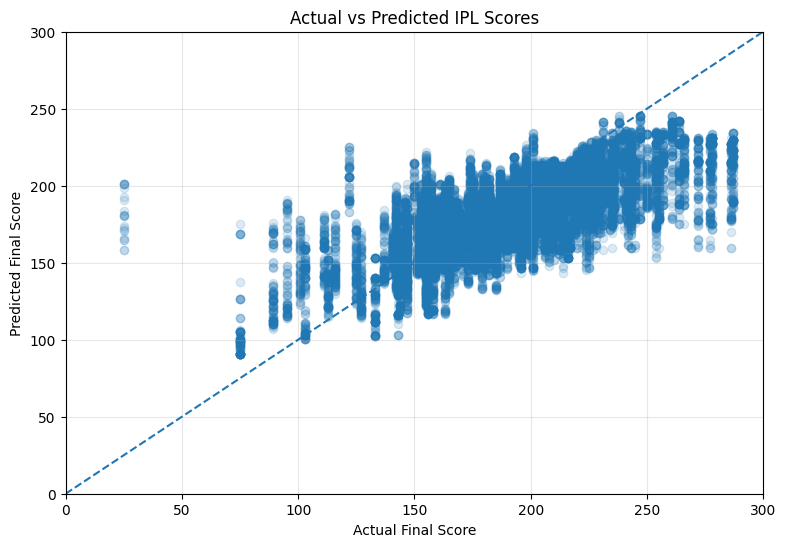

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(
    prediction_results['Actual Score'],
    prediction_results['Predicted Score'],
    alpha=0.15
)

# Perfect prediction reference line
plt.plot(
    [0, 300],
    [0, 300],
    linestyle='--'
)

plt.xlabel('Actual Final Score')
plt.ylabel('Predicted Final Score')
plt.title('Actual vs Predicted IPL Scores')

plt.xlim(0, 300)
plt.ylim(0, 300)

plt.grid(alpha=0.3)
plt.show()

In [ ]:
stage_comparison = error_analysis.groupby(
    'innings_stage',
    observed=False
).agg(
    Actual_Average=('final_score', 'mean'),
    Predicted_Average=('Predicted Score', 'mean'),
    MAE=('Error', lambda x: x.abs().mean())
)

stage_comparison

,Actual_Average,Predicted_Average,MAE
innings_stage,,,
Overs 1-5,190.699482,175.398498,30.626057
Overs 6-10,191.256881,181.608374,23.167841
Overs 11-15,191.878783,185.313759,16.787407
Overs 16-20,194.371004,189.672310,10.146310


In [ ]:
year_comparison = error_analysis.groupby('year').agg(
    Actual_Average=('final_score', 'mean'),
    Predicted_Average=('Predicted Score', 'mean'),
    Average_Error=('Error', 'mean'),
    MAE=('Error', lambda x: x.abs().mean()),
    Samples=('Error', 'count')
)

year_comparison

,Actual_Average,Predicted_Average,Average_Error,MAE,Samples
year,,,,,
2024,189.972002,179.557875,10.414127,20.965639,8465
2025,190.488029,183.458416,7.029614,19.347415,8688
2026,195.566064,185.637767,9.928297,20.632640,8681


In [ ]:
# we will apply 4 models
# Recreate training and testing datasets
train_data_stage = snapshots_with_year.loc[
    X_train_time.index
].copy()

test_data_stage = snapshots_with_year.loc[
    X_test_time.index
].copy()

# Define innings stages
stage_bins = [0, 30, 60, 90, 120]

stage_labels = [
    'Overs 1-5',
    'Overs 6-10',
    'Overs 11-15',
    'Overs 16-20'
]

# Assign stages to training data
train_data_stage['innings_stage'] = pd.cut(
    train_data_stage['legal_balls'],
    bins=stage_bins,
    labels=stage_labels
)

# Assign stages to testing data
test_data_stage['innings_stage'] = pd.cut(
    test_data_stage['legal_balls'],
    bins=stage_bins,
    labels=stage_labels
)

# Display snapshot counts
print("TRAINING DATA")
print(train_data_stage['innings_stage'].value_counts().sort_index())

print("\nTESTING DATA")
print(test_data_stage['innings_stage'].value_counts().sort_index())

TRAINING DATA
innings_stage
Overs 1-5      30720
Overs 6-10     30678
Overs 11-15    30475
Overs 16-20    29790
Name: count, dtype: int64

TESTING DATA
innings_stage
Overs 1-5      6562
Overs 6-10     6540
Overs 11-15    6476
Overs 16-20    6256
Name: count, dtype: int64


In [ ]:
# Create a separate encoder for this experiment
stage_encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

# Fit encoder on training venues
train_venue_stage = stage_encoder.fit_transform(
    train_data_stage[['venue']]
)

# Transform testing venues
test_venue_stage = stage_encoder.transform(
    test_data_stage[['venue']]
)

# Combine numerical and venue features
X_train_stage_all = np.concatenate(
    [
        train_data_stage[reduced_features].values,
        train_venue_stage
    ],
    axis=1
)

X_test_stage_all = np.concatenate(
    [
        test_data_stage[reduced_features].values,
        test_venue_stage
    ],
    axis=1
)

print("Training features:", X_train_stage_all.shape)
print("Testing features:", X_test_stage_all.shape)

print("Number of features:", X_train_stage_all.shape[1])

Training features: (121663, 63)
Testing features: (25834, 63)
Number of features: 63


In [ ]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

stage_models = {}
stage_predictions = {}
stage_results = []

for stage in stage_labels:

    print(f"Training {stage}...")

    # Get training and testing row positions
    train_mask = (
        train_data_stage['innings_stage'] == stage
    ).values

    test_mask = (
        test_data_stage['innings_stage'] == stage
    ).values

    # Select features
    X_train = X_train_stage_all[train_mask]
    X_test = X_test_stage_all[test_mask]

    # Select target
    y_train = train_data_stage.loc[
        train_mask, 'final_score'
    ]

    y_test = test_data_stage.loc[
        test_mask, 'final_score'
    ]

    # Create model
    model = GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        min_samples_leaf=10,
        random_state=42
    )

    # Train
    model.fit(X_train, y_train)

    # Predict
    predictions = model.predict(X_test)

    # Save model and predictions
    stage_models[stage] = model
    stage_predictions[stage] = predictions

    # Evaluate
    mae = mean_absolute_error(y_test, predictions)

    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )

    stage_results.append({
        'Stage': stage,
        'MAE': mae,
        'RMSE': rmse,
        'Samples': len(y_test)
    })

    print(f"Completed {stage} | MAE: {mae:.2f}")

stage_results_df = pd.DataFrame(stage_results)

stage_results_df

Training Overs 1-5...
Completed Overs 1-5 | MAE: 31.34
Training Overs 6-10...
Completed Overs 6-10 | MAE: 24.40
Training Overs 11-15...
Completed Overs 11-15 | MAE: 15.73
Training Overs 16-20...
Completed Overs 16-20 | MAE: 7.74


,Stage,MAE,RMSE,Samples
0,Overs 1-5,31.335544,39.451876,6562
1,Overs 6-10,24.397241,30.225523,6540
2,Overs 11-15,15.731900,20.767797,6476
3,Overs 16-20,7.738129,10.498577,6256


In [ ]:
stage_weighted_mae = (
    stage_results_df['MAE'] * stage_results_df['Samples']
).sum() / stage_results_df['Samples'].sum()

print("Stage-specific overall MAE:", stage_weighted_mae)
print("Single-model overall MAE:", 20.309531)
print("Improvement:", 20.309531 - stage_weighted_mae)

Stage-specific overall MAE: 19.953213487829643
Single-model overall MAE: 20.309531
Improvement: 0.35631751217035657


#### HYBRID MODEL

In [ ]:
hybrid_predictions = venue_predictions.copy()

for stage in ['Overs 11-15', 'Overs 16-20']:

    mask = (
        test_data_stage['innings_stage'] == stage
    ).values

    hybrid_predictions[mask] = stage_predictions[stage]

hybrid_mae = mean_absolute_error(
    y_test_time,
    hybrid_predictions
)

hybrid_rmse = np.sqrt(
    mean_squared_error(y_test_time, hybrid_predictions)
)

print("Hybrid MAE:", hybrid_mae)
print("Hybrid RMSE:", hybrid_rmse)

Hybrid MAE: 19.461770740730056
Hybrid RMSE: 26.91902842077816


In [ ]:
hybrid_error_analysis = pd.DataFrame({
    'Actual Score': y_test_time.values,
    'Predicted Score': hybrid_predictions,
    'Legal Balls': test_data_stage['legal_balls'].values
})

hybrid_error_analysis['Error'] = (
    hybrid_error_analysis['Actual Score']
    - hybrid_error_analysis['Predicted Score']
)

hybrid_error_analysis['Stage'] = pd.cut(
    hybrid_error_analysis['Legal Balls'],
    bins=[0, 30, 60, 90, 120],
    labels=stage_labels
)

hybrid_stage_results = hybrid_error_analysis.groupby(
    'Stage', observed=False
).agg(
    MAE=('Error', lambda x: x.abs().mean()),
    RMSE=('Error', lambda x: np.sqrt((x ** 2).mean())),
    Samples=('Error', 'count')
)

hybrid_stage_results

,MAE,RMSE,Samples
Stage,,,
Overs 1-5,30.626057,38.605101,6562
Overs 6-10,23.167841,28.888297,6540
Overs 11-15,15.731900,20.767797,6476
Overs 16-20,7.738129,10.498577,6256


In [ ]:

# Final hybrid prediction function

def predict_final_score(
    current_runs,
    wickets,
    legal_balls,
    venue,
    runs_last_30_balls,
    runs_last_6_balls,
    runs_last_12_balls
):

    # Validate input
    if not 1 <= legal_balls <= 120:
        raise ValueError(
            "Legal balls must be between 1 and 120."
        )

    if not 0 <= wickets <= 10:
        raise ValueError(
            "Wickets must be between 0 and 10."
        )

    if current_runs < 0:
        raise ValueError(
            "Current runs cannot be negative."
        )

    # Calculate current run rate
    current_run_rate = (
        current_runs / legal_balls
    ) * 6

    # Prepare numerical features
    input_features = pd.DataFrame([{
        'legal_balls': legal_balls,
        'current_runs': current_runs,
        'wickets': wickets,
        'current_run_rate': current_run_rate,
        'runs_last_30_balls': runs_last_30_balls,
        'runs_last_6_balls': runs_last_6_balls,
        'runs_last_12_balls': runs_last_12_balls
    }])

    input_features = input_features[reduced_features]

    venue_input = pd.DataFrame({
        'venue': [venue]
    })

    # First 10 overs: Venue model
    if legal_balls <= 60:

        venue_encoded = (
            original_venue_encoder.transform(
                venue_input
            )
        )

        venue_columns = (
            original_venue_encoder.get_feature_names_out(
                ['venue']
            )
        )

        encoded_df = pd.DataFrame(
            venue_encoded,
            columns=venue_columns
        )

        final_input = pd.concat(
            [
                input_features.reset_index(drop=True),
                encoded_df
            ],
            axis=1
        )

        prediction = venue_model.predict(
            final_input
        )[0]

    # Overs 11-15: Stage-specific model
    elif legal_balls <= 90:

        stage = 'Overs 11-15'

        venue_encoded = (
            stage_encoder.transform(venue_input)
        )

        final_input = np.concatenate(
            [
                input_features.values,
                venue_encoded
            ],
            axis=1
        )

        prediction = stage_models[stage].predict(
            final_input
        )[0]

    # Overs 16-20: Stage-specific model
    else:

        stage = 'Overs 16-20'

        venue_encoded = (
            stage_encoder.transform(venue_input)
        )

        final_input = np.concatenate(
            [
                input_features.values,
                venue_encoded
            ],
            axis=1
        )

        prediction = stage_models[stage].predict(
            final_input
        )[0]

    # Final score cannot be lower than current score
    prediction = max(current_runs, prediction)

    return int(round(prediction))


# Test the prediction function

test_prediction = predict_final_score(
    current_runs=152,
    wickets=3,
    legal_balls=101,
    venue='Narendra Modi Stadium, Ahmedabad',
    runs_last_30_balls=55,
    runs_last_6_balls=12,
    runs_last_12_balls=22
)

print("Predicted final score:", test_prediction)


Predicted final score: 191


In [ ]:

# Save the final hybrid model and preprocessing artifacts

import joblib
import os

os.makedirs('../models', exist_ok=True)

model_artifacts = {
    'venue_model': venue_model,
    'original_venue_encoder': original_venue_encoder,
    'stage_models': stage_models,
    'stage_encoder': stage_encoder,
    'reduced_features': reduced_features,
    'stage_labels': stage_labels,

    'hybrid_strategy': {
        'venue_model_max_balls': 60,
        'stage_11_15_max_balls': 90
    }
}

model_path = '../models/ipl_score_prediction.pkl'

joblib.dump(
    model_artifacts,
    model_path
)

print("Hybrid model saved successfully!")
print("Model path:", model_path)


Models saved successfully!


In [ ]:

# Load and verify saved model artifacts

import joblib

loaded_artifacts = joblib.load(
    '../models/ipl_score_prediction.pkl'
)

required_components = [
    'venue_model',
    'original_venue_encoder',
    'stage_models',
    'stage_encoder',
    'reduced_features',
    'stage_labels',
    'hybrid_strategy'
]

# Verify all components are present
for component in required_components:

    assert component in loaded_artifacts, (
        f"Missing component: {component}"
    )

print("Model loaded successfully!")

print("\nLoaded components:")

for component in loaded_artifacts:
    print("-", component)

print(
    "\nVenue model features:",
    loaded_artifacts['venue_model'].n_features_in_
)

print(
    "\nStage models:",
    list(loaded_artifacts['stage_models'].keys())
)


Loaded components:
venue_model
original_venue_encoder
stage_models
stage_encoder
reduced_features
